In [26]:
import inspect
import digits.data
print("Loaded from:", digits.data.__file__)
print("Signature:  ", inspect.signature(digits.data.make_loaders))

Loaded from: /Users/manvigupta/PycharmProjects/KaggleComp/src/digits/data.py
Signature:   (train_csv, val_size=0.1, batch_size=128, seed=42, augment=False)


In [27]:
print("Working directory:", os.getcwd())

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
DATA = ROOT / "data"
print("Project root:", ROOT)
print("Files in data/:", [p.name for p in DATA.iterdir()])

Working directory: /Users/manvigupta/PycharmProjects/KaggleComp/notebooks
Project root: /Users/manvigupta/PycharmProjects/KaggleComp
Files in data/: ['test.csv', 'README.md', 'train.csv']


In [28]:
from digits.data import make_loaders
from digits.models import MLP, CNN, count_params
from digits.train import set_seed, fit, get_device
from pathlib import Path
import os
import matplotlib.pyplot as plt
import numpy as np

In [29]:
train_loader, val_loader, (mean, std) = make_loaders("../data/train.csv")
print(f"mean={mean:.4f}, std={std:.4f}")
print("train batches:", len(train_loader), "| val batches:", len(val_loader))

images, labels = next(iter(train_loader))
print("batch shape:", images.shape, "| labels shape:", labels.shape)

mean=0.1310, std=0.3085
train batches: 296 | val batches: 17
batch shape: torch.Size([128, 1, 28, 28]) | labels shape: torch.Size([128])


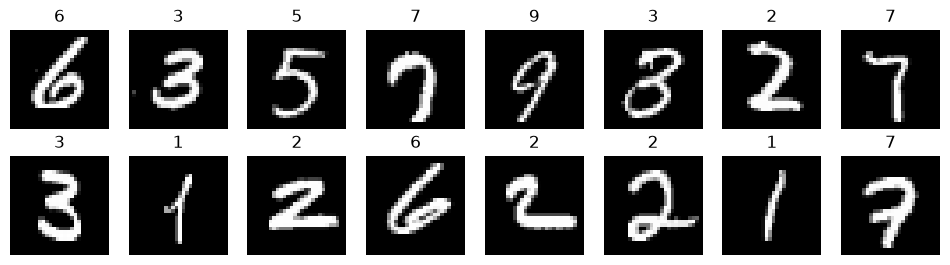

val class counts: [413 468 418 435 407 380 414 440 406 419]


In [30]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for ax, img, lbl in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(int(lbl)); ax.axis("off")
plt.show()

print("val class counts:", np.bincount(val_loader.dataset.labels.numpy()))

In [31]:
from digits.train import set_seed, fit, get_device
from digits.models import MLP, CNN

print("Device:", get_device())

set_seed(42)
mlp = MLP()
hist_mlp = fit(mlp, train_loader, val_loader, epochs=10)

Device: mps
Epoch 01/10 | train loss 0.3310 acc 0.9034 | val loss 0.1680 acc 0.9488 | 1.6s
Epoch 02/10 | train loss 0.1290 acc 0.9609 | val loss 0.1177 acc 0.9660 | 1.1s
Epoch 03/10 | train loss 0.0850 acc 0.9739 | val loss 0.1010 acc 0.9702 | 1.2s
Epoch 04/10 | train loss 0.0581 acc 0.9817 | val loss 0.0915 acc 0.9707 | 1.1s
Epoch 05/10 | train loss 0.0440 acc 0.9861 | val loss 0.0926 acc 0.9707 | 1.2s
Epoch 06/10 | train loss 0.0350 acc 0.9893 | val loss 0.0913 acc 0.9757 | 1.2s
Epoch 07/10 | train loss 0.0288 acc 0.9906 | val loss 0.0975 acc 0.9731 | 1.2s
Epoch 08/10 | train loss 0.0264 acc 0.9912 | val loss 0.0957 acc 0.9779 | 1.3s
Epoch 09/10 | train loss 0.0199 acc 0.9933 | val loss 0.0955 acc 0.9788 | 1.3s
Epoch 10/10 | train loss 0.0167 acc 0.9947 | val loss 0.1124 acc 0.9729 | 1.2s
Restored best weights (val acc 0.9788)


In [32]:
set_seed(42)
cnn = CNN()
hist_cnn = fit(cnn, train_loader, val_loader, epochs=10)

Epoch 01/10 | train loss 0.2265 acc 0.9267 | val loss 0.0756 acc 0.9795 | 14.7s
Epoch 02/10 | train loss 0.0525 acc 0.9833 | val loss 0.0488 acc 0.9857 | 14.1s
Epoch 03/10 | train loss 0.0355 acc 0.9889 | val loss 0.0334 acc 0.9900 | 16.4s
Epoch 04/10 | train loss 0.0241 acc 0.9924 | val loss 0.0433 acc 0.9869 | 19.4s
Epoch 05/10 | train loss 0.0179 acc 0.9943 | val loss 0.0567 acc 0.9869 | 18.0s
Epoch 06/10 | train loss 0.0158 acc 0.9949 | val loss 0.0495 acc 0.9862 | 19.6s
Epoch 07/10 | train loss 0.0119 acc 0.9960 | val loss 0.0404 acc 0.9888 | 15.3s
Epoch 08/10 | train loss 0.0095 acc 0.9969 | val loss 0.0539 acc 0.9876 | 14.0s
Epoch 09/10 | train loss 0.0098 acc 0.9965 | val loss 0.0505 acc 0.9898 | 14.8s
Epoch 10/10 | train loss 0.0090 acc 0.9968 | val loss 0.0465 acc 0.9890 | 16.1s
Restored best weights (val acc 0.9900)


In [33]:
set_seed(42)
cnn_bn = CNN(batchnorm=True, dropout=0.4)
hist_cnn_bn = fit(cnn_bn, train_loader, val_loader, epochs=10)

Epoch 01/10 | train loss 0.2191 acc 0.9311 | val loss 0.0529 acc 0.9836 | 16.7s
Epoch 02/10 | train loss 0.0720 acc 0.9779 | val loss 0.0399 acc 0.9883 | 17.8s
Epoch 03/10 | train loss 0.0596 acc 0.9822 | val loss 0.0416 acc 0.9860 | 15.6s
Epoch 04/10 | train loss 0.0521 acc 0.9840 | val loss 0.0368 acc 0.9898 | 26.4s
Epoch 05/10 | train loss 0.0426 acc 0.9864 | val loss 0.0337 acc 0.9910 | 18.6s
Epoch 06/10 | train loss 0.0394 acc 0.9881 | val loss 0.0323 acc 0.9912 | 15.2s
Epoch 07/10 | train loss 0.0327 acc 0.9903 | val loss 0.0500 acc 0.9867 | 15.6s
Epoch 08/10 | train loss 0.0318 acc 0.9894 | val loss 0.0395 acc 0.9886 | 15.7s
Epoch 09/10 | train loss 0.0325 acc 0.9897 | val loss 0.0367 acc 0.9907 | 17.5s
Epoch 10/10 | train loss 0.0298 acc 0.9906 | val loss 0.0463 acc 0.9876 | 13.8s
Restored best weights (val acc 0.9912)


In [34]:
train_loader_aug, val_loader_aug, _ = make_loaders(DATA / "train.csv", augment=True)

set_seed(42)
cnn_best = CNN(batchnorm=True, dropout=0.4)
hist_cnn_best = fit(cnn_best, train_loader_aug, val_loader_aug, epochs=15,
                    lr=3e-3, use_scheduler=True)

Epoch 01/15 | train loss 0.7846 acc 0.7467 | val loss 0.1036 acc 0.9664 | 18.2s
Epoch 02/15 | train loss 0.1886 acc 0.9427 | val loss 0.1982 acc 0.9431 | 23.4s
Epoch 03/15 | train loss 0.1466 acc 0.9550 | val loss 0.0479 acc 0.9852 | 21.7s
Epoch 04/15 | train loss 0.1364 acc 0.9592 | val loss 0.0999 acc 0.9757 | 22.2s
Epoch 05/15 | train loss 0.1148 acc 0.9666 | val loss 0.0393 acc 0.9893 | 32.2s
Epoch 06/15 | train loss 0.0919 acc 0.9719 | val loss 0.0411 acc 0.9871 | 18.8s
Epoch 07/15 | train loss 0.0807 acc 0.9762 | val loss 0.0416 acc 0.9886 | 23.2s
Epoch 08/15 | train loss 0.0713 acc 0.9786 | val loss 0.0423 acc 0.9898 | 18.8s
Epoch 09/15 | train loss 0.0602 acc 0.9824 | val loss 0.0242 acc 0.9931 | 21.1s
Epoch 10/15 | train loss 0.0537 acc 0.9842 | val loss 0.0257 acc 0.9933 | 22.8s
Epoch 11/15 | train loss 0.0457 acc 0.9867 | val loss 0.0210 acc 0.9950 | 18.5s
Epoch 12/15 | train loss 0.0414 acc 0.9873 | val loss 0.0202 acc 0.9940 | 17.9s
Epoch 13/15 | train loss 0.0336 acc 0.99

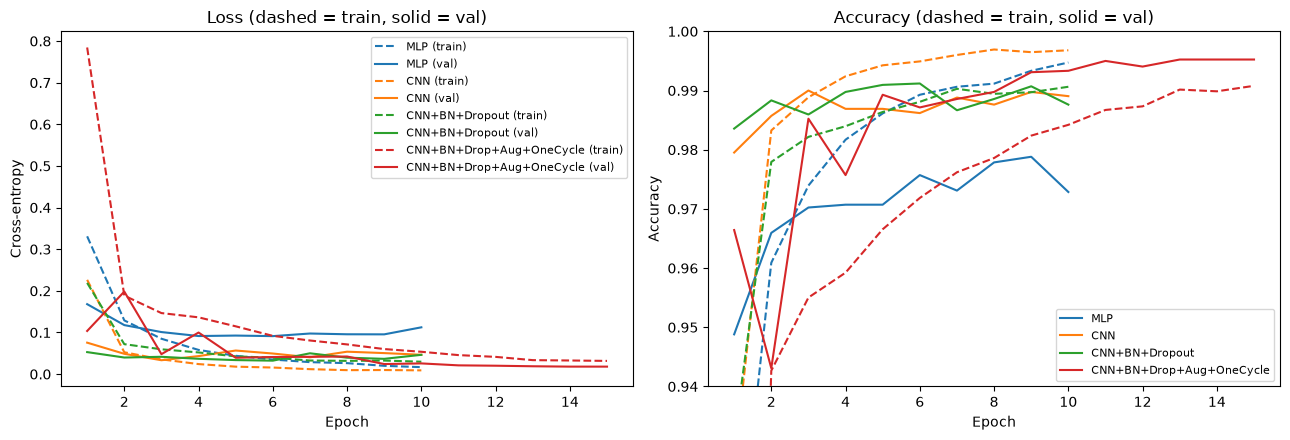

In [35]:
from digits.plots import plot_history, plot_confusion, plot_misclassified
from digits.predict import predict_logits, make_submission

RESULTS = ROOT / "results"
plot_history(
    {"MLP": hist_mlp, "CNN": hist_cnn, "CNN+BN+Dropout": hist_cnn_bn,
     "CNN+BN+Drop+Aug+OneCycle": hist_cnn_best},
    save_path=RESULTS / "training_curves.png",
)

Validation accuracy: 0.9952  |  errors: 20


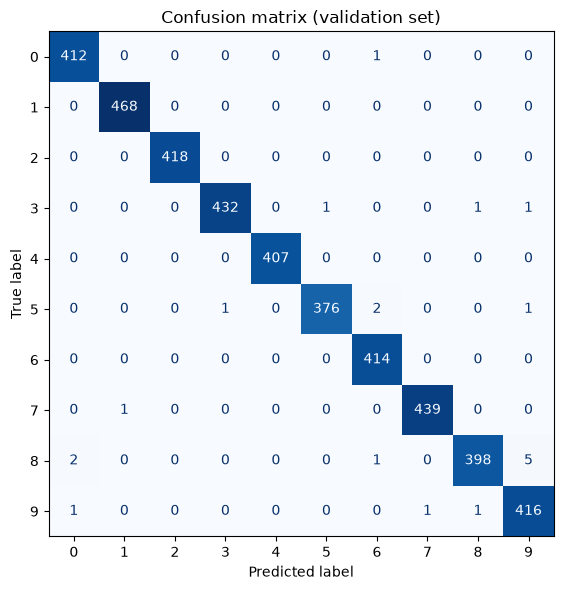

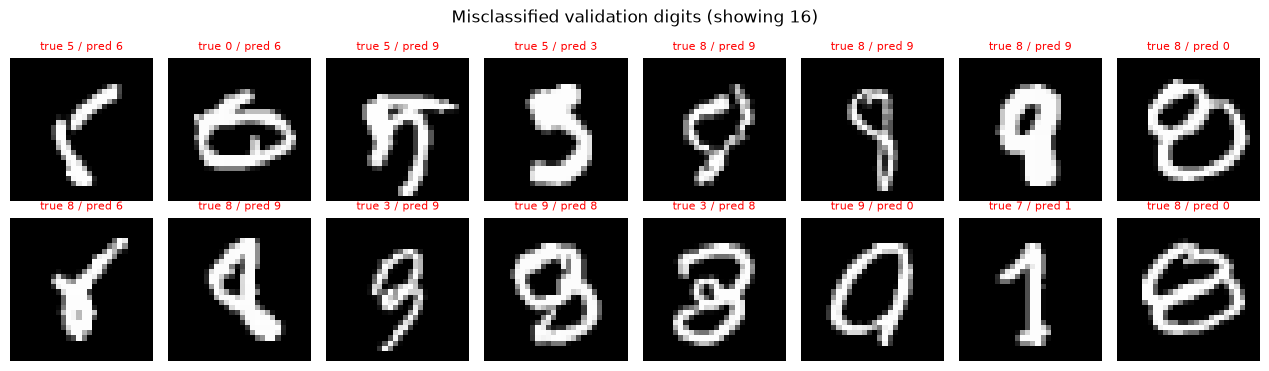

In [36]:
val_logits = predict_logits(cnn_best, val_loader_aug)
y_pred = val_logits.argmax(dim=1).numpy()
y_true = val_loader_aug.dataset.labels.numpy()
print(f"Validation accuracy: {(y_pred == y_true).mean():.4f}  |  errors: {(y_pred != y_true).sum()}")

plot_confusion(y_true, y_pred, save_path=RESULTS / "confusion_matrix.png")
plot_misclassified(val_loader_aug.dataset.images, y_true, y_pred,
                   save_path=RESULTS / "misclassified.png")